In [16]:
# Environment Setup & Dark Theme Configuration

import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Visual Setup for Dark Cyber Theme
plt.style.use('dark_background')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Ensure required project directories exist
os.makedirs("../docs/diagrams", exist_ok=True)
print("[✓] Environment initialized and theme set to dark.")

[✓] Environment initialized and theme set to dark.


In [17]:
# Data Ingestion & Sanitization

DATA_PATH = "../data/processed/top12_features_sample.csv"
print(f"[+] Ingesting processed dataset from: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

# Sanitize potential infinity and null values
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

print(f"[✓] Data Loaded Successfully: {df.shape[0]} rows, {df.shape[1]} columns.")
df.head(3)

[+] Ingesting processed dataset from: ../data/processed/top12_features_sample.csv
[✓] Data Loaded Successfully: 50000 rows, 13 columns.


,ICMP,TCP,UDP,Protocol Type,psh_flag_number,syn_flag_number,syn_count,ack_count,Header_Length,fin_count,fin_flag_number,rst_flag_number,Label
0,0.0,1.00,0.0,6,0.0,0.0,0,10,32.0,0,0.0,0.0,BENIGN
1,0.0,0.98,0.0,6,0.0,0.0,0,0,19.6,0,0.0,0.0,DOS-TCP_FLOOD
2,0.0,1.00,0.0,6,0.0,0.0,0,0,20.0,100,1.0,1.0,DDOS-RSTFINFLOOD


C:\Users\suraj\AppData\Local\Temp\ipykernel_11712\292163735.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=top_classes.values, y=top_classes.index, palette=palette)


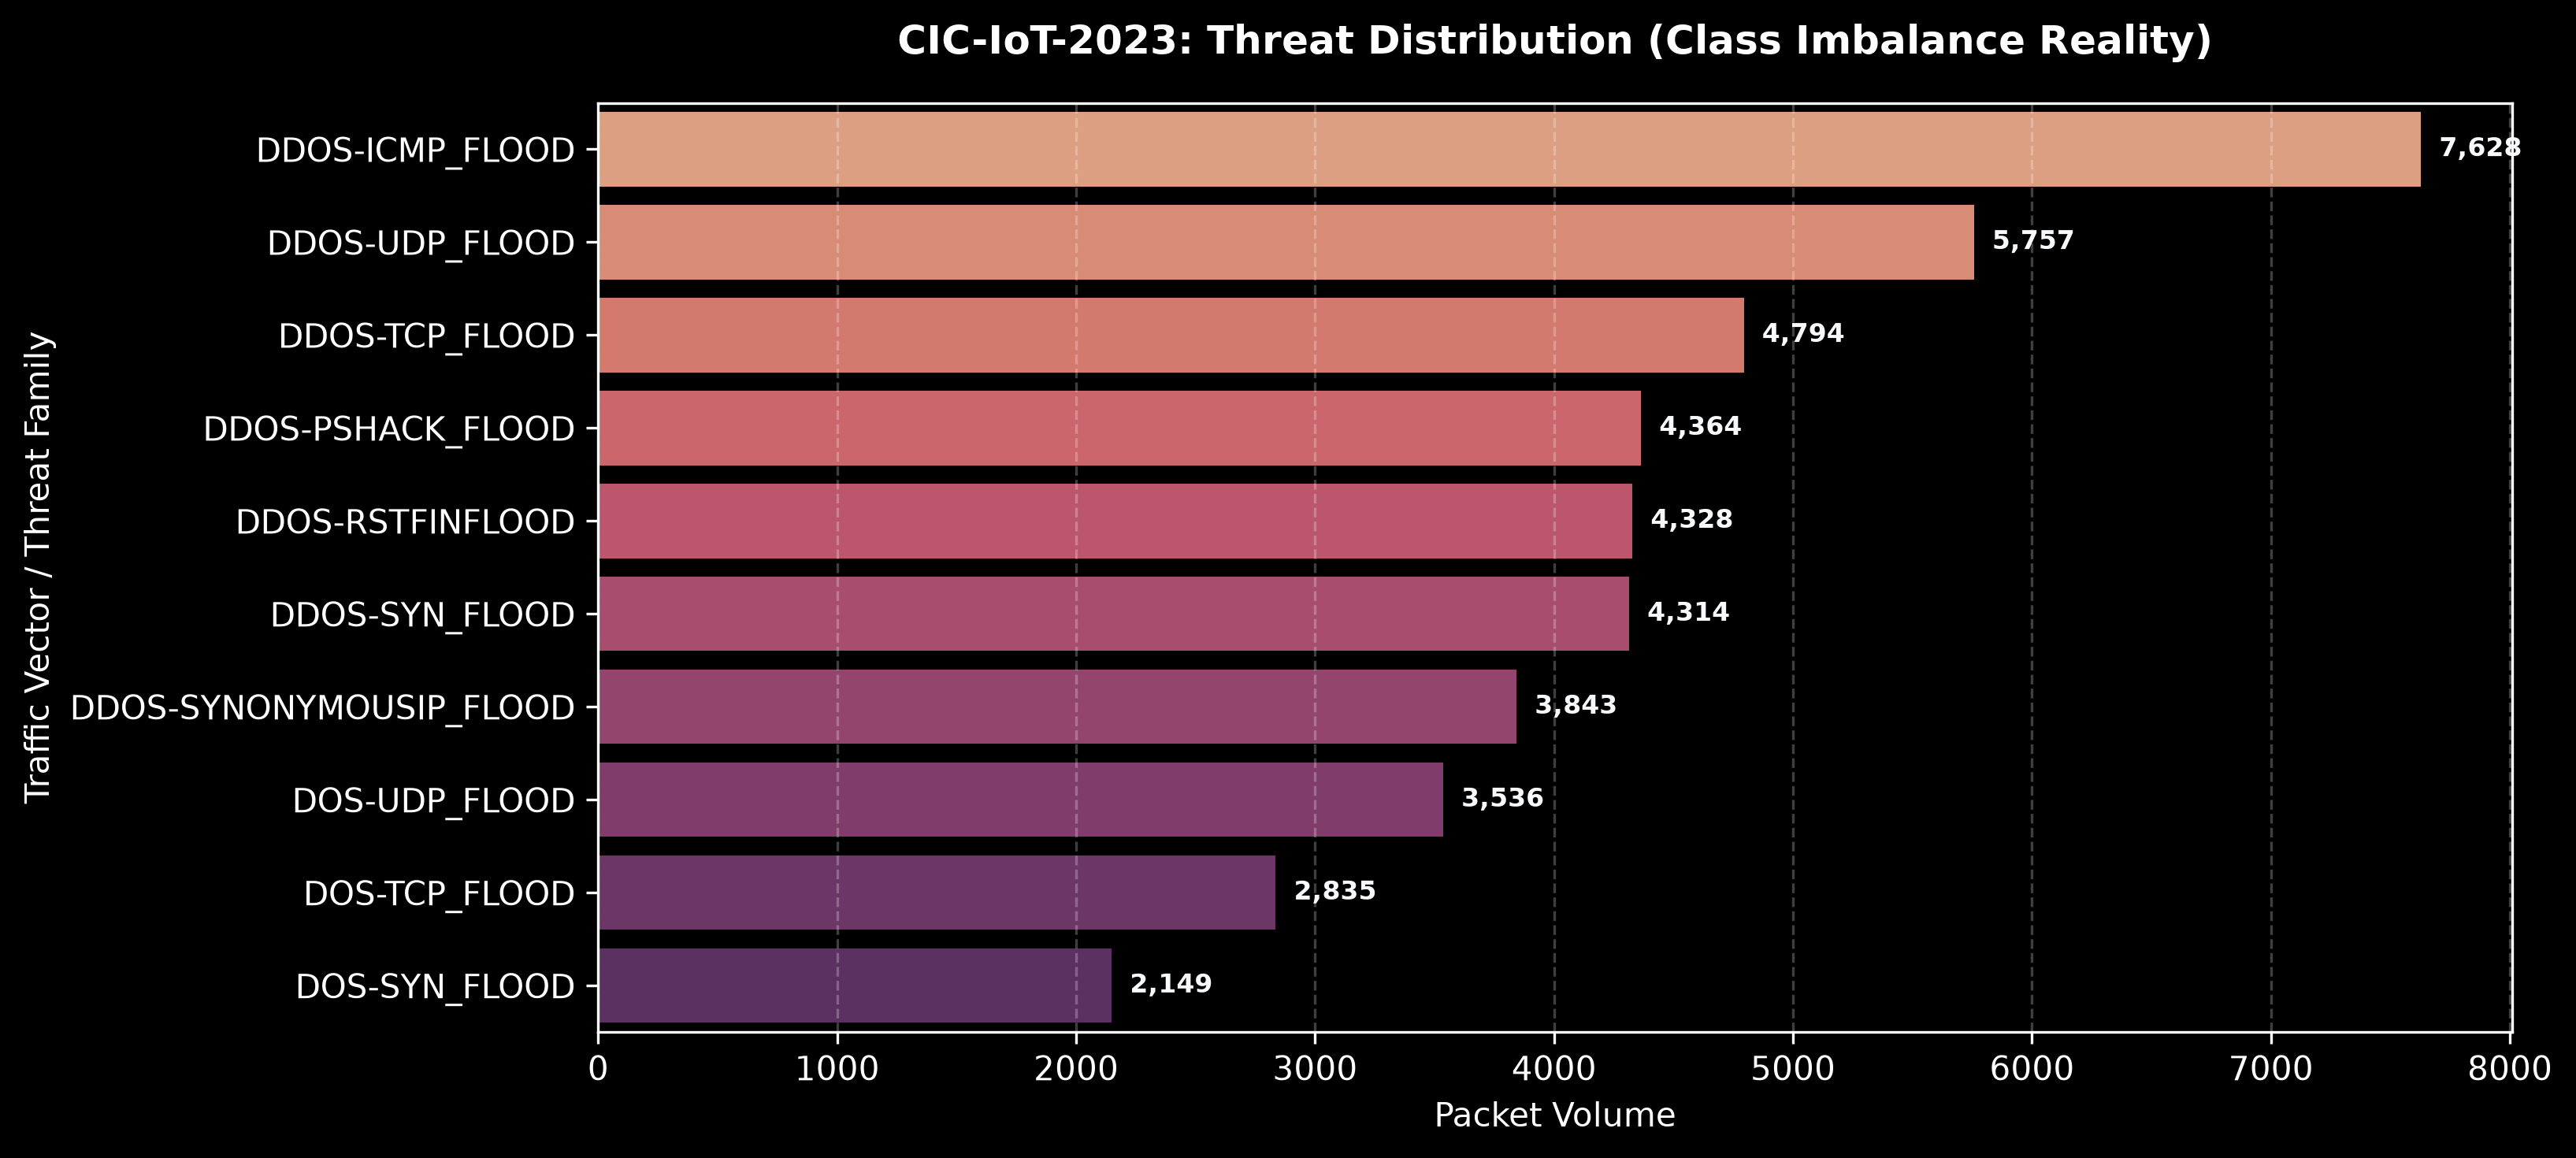

[✓] Saved visual: docs/diagrams/eda_class_distribution.png


In [18]:
# Exploratory Data Analysis — Class Imbalance Distribution

# Calculate top 10 attack classes
top_classes = df['Label'].value_counts().head(10)

plt.figure(figsize=(11, 5), dpi=300)
palette = sns.color_palette("flare", len(top_classes))
ax = sns.barplot(x=top_classes.values, y=top_classes.index, palette=palette)

# Add exact packet counts on bars
for bar in ax.patches:
    val = int(bar.get_width())
    ax.text(
        bar.get_x() + bar.get_width() + (top_classes.max() * 0.01),
        bar.get_y() + bar.get_height() / 2.0,
        f"{val:,}",
        va='center',
        ha='left',
        color='#f8fafc',
        fontsize=8,
        fontweight='bold'
    )

plt.title("CIC-IoT-2023: Threat Distribution (Class Imbalance Reality)", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Packet Volume", fontsize=10)
plt.ylabel("Traffic Vector / Threat Family", fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.25)
plt.tight_layout()

plt.savefig("../docs/diagrams/eda_class_distribution.png", dpi=300)
plt.show()
print("[✓] Saved visual: docs/diagrams/eda_class_distribution.png")

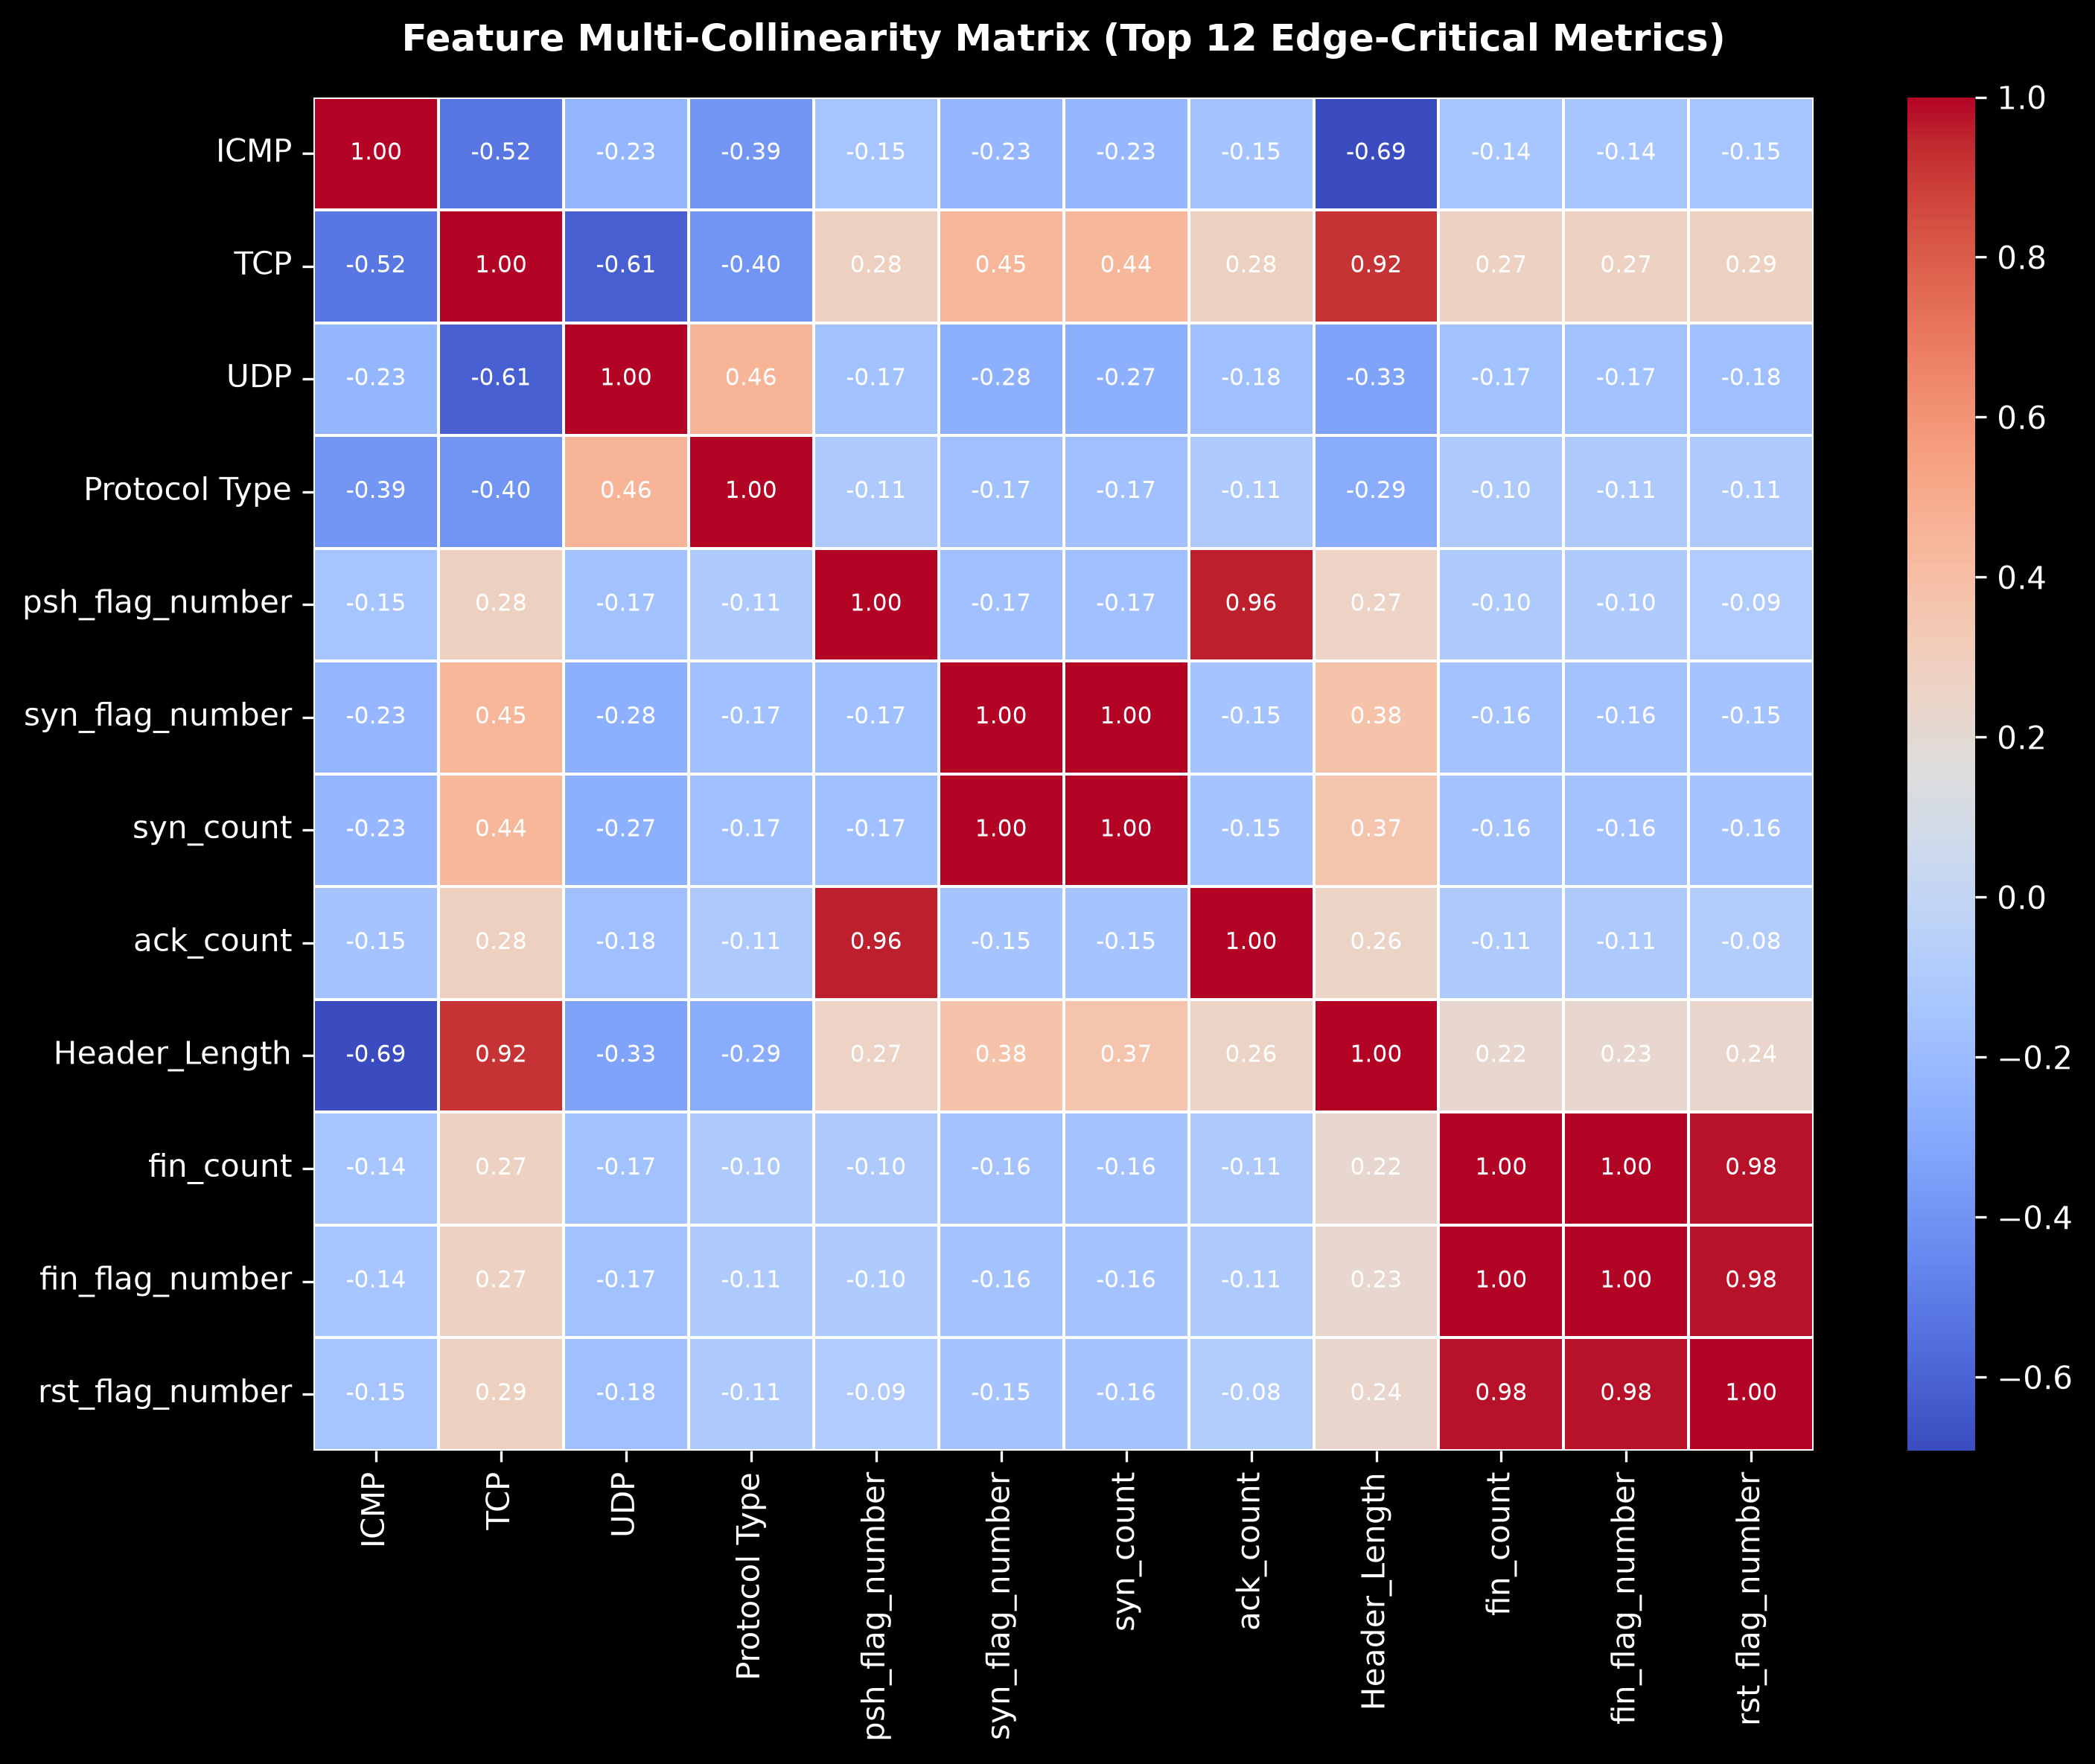

[✓] Saved visual: docs/diagrams/eda_feature_correlation.png


In [19]:
# Non-Collinearity Check — Feature Correlation Matrix

plt.figure(figsize=(10, 8), dpi=300)

# Isolate features from target label
features_only = df.drop(columns=['Label'])
corr_matrix = features_only.corr()

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar=True,
    annot_kws={"size": 7.5, "color": "white"}
)

plt.title("Feature Multi-Collinearity Matrix (Top 12 Edge-Critical Metrics)", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()

plt.savefig("../docs/diagrams/eda_feature_correlation.png", dpi=300)
plt.show()
print("[✓] Saved visual: docs/diagrams/eda_feature_correlation.png")